In [1]:
#| echo: false
#| warning: false
#| output: asis

from IPython.display import Markdown, display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.formula.api import ols
from statsmodels.iolib.summary2 import summary_col

# Не показывать Warning
import warnings
warnings.simplefilter(action='ignore', category=Warning)

# Настройки оформления графиков
plt.rcParams['figure.figsize'] = (8.5, 6)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14

CONST_NAMES = ('const', 'Intercept')


def fmt(x, decimals=3):
    """Число с заданным числом знаков; оценка, которая округляется до нуля, — с тремя значащими цифрами."""
    if pd.isna(x):
        return ''
    text = f'{x:.{decimals}f}'
    if float(text) == 0:
        return f'{x:.3g}' if x != 0 else f'{0:.{decimals}f}'
    return text


def fmt_p(p, decimals=3):
    """P-значение: меньше 0.001 печатается как «<0.001»."""
    return '<0.001' if p < 0.001 else f'{p:.{decimals}f}'


def errors_text(res, case='nom'):
    """Название типа стандартных ошибок подгонки: 'nom' — «неробастные», 'dat' — «по неробастным …»."""
    cov_type = getattr(res, 'cov_type', 'nonrobust')
    if cov_type == 'nonrobust':
        return {'nom': 'неробастные стандартные ошибки',
                'dat': 'по неробастным стандартным ошибкам'}[case]
    return {'nom': f'робастные стандартные ошибки, {cov_type}',
            'dat': f'по робастным стандартным ошибкам {cov_type}'}[case]


def fit_ols(formula, data, robust=False, **kwargs):
    """МНК-подгонка; robust=True — робастные ошибки HC3. Всегда t- и F-распределения (use_t=True)."""
    cov_type = 'HC3' if robust else 'nonrobust'
    return ols(formula, data=data).fit(cov_type=cov_type, use_t=True, **kwargs)


def show_table(df, index=True, align=None):
    """Таблица pandas в Markdown; числа должны быть заранее превращены в строки через fmt."""
    display(Markdown('\n\n' + df.to_markdown(index=index, colalign=align, disable_numparse=True) + '\n\n'))


def nobs_text(res):
    """Строка «Модель была подогнана по N наблюдениям»."""
    n = int(res.nobs)
    word = 'наблюдению' if n % 10 == 1 and n % 100 != 11 else 'наблюдениям'
    return f'Модель была подогнана по {n} {word}.'


def show_coefs(res, decimals=3, show_nobs=True):
    """Оценки коэффициентов: вертикальная таблица «Переменная | Оценка» и число наблюдений."""
    cov_type = getattr(res, 'cov_type', 'nonrobust')
    column = 'Оценка' if cov_type == 'nonrobust' else f'Оценка ({cov_type})'
    table = pd.DataFrame({'Переменная': res.params.index,
                          column: [fmt(b, decimals) for b in res.params]})
    text = table.to_markdown(index=False, colalign=('left', 'right'), disable_numparse=True)
    if show_nobs:
        text += '\n\n' + nobs_text(res)
    display(Markdown('\n\n' + text + '\n\n'))


def display_answer(text, use_callout=True, theme='note', title='Критическое значение'):
    """Ответ в рамке (callout): theme='note' — число, 'tip' — вывод, 'important' — условие."""
    if use_callout:
        head = f'title="{title}" ' if title else ''
        output_md = f'\n\n::: {{.callout-{theme} {head}icon="true"}}\n{text}\n:::\n\n'
    elif title:
        output_md = f'\n\n**{title}:** {text}\n\n'
    else:
        output_md = f'\n\n{text}\n\n'
    display(Markdown(output_md))


def show_conditions(level, errors=None, hypothesis=None, extra=()):
    """Блок «Условия теста»: уровень значимости (доля или список долей), тип ошибок, гипотеза формулой."""
    levels = level if isinstance(level, (list, tuple)) else [level]
    items = ['уровень значимости: **' + ' и '.join(f'{a * 100:g}%' for a in levels) + '**']
    if errors:
        items.append(f'стандартные ошибки: **{errors}**')
    hypotheses = [hypothesis] if isinstance(hypothesis, str) else list(hypothesis or [])
    if len(hypotheses) == 1:
        items.append(f'гипотеза: {hypotheses[0]}')
    else:
        items += [f'гипотеза {i}: {h}' for i, h in enumerate(hypotheses, start=1)]
    items += list(extra)
    display_answer('\n'.join(f'- {item}' for item in items), theme='important', title='Условия теста')


def signif_stars(p):
    """Коды значимости: *** p<0.01, ** p<0.05, * p<0.1."""
    return '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.1 else ''


SIGNIF_LEGEND = '*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$'


def print_regression_summary(res, decimals=3, show_signif=True):
    """Таблица t-теста: Coef., Std.Err., t-value, p-value, Signif. Заголовок называет тип ошибок."""
    title = f'**Результаты $t$-теста для коэффициентов ({errors_text(res)}):**'
    table = pd.DataFrame({
        'Coef.': [fmt(b, decimals) for b in res.params],
        'Std.Err.': [fmt(s, decimals) for s in res.bse],
        't-value': [fmt(t, decimals) for t in res.tvalues],
        'p-value': [fmt_p(p, decimals) for p in res.pvalues],
    }, index=res.params.index)
    legend = ''
    if show_signif:
        table['Signif.'] = ['' if name in CONST_NAMES else signif_stars(p)
                            for name, p in res.pvalues.items()]
        legend = '\n\n' + SIGNIF_LEGEND
    align = ('left',) + ('right',) * 4 + (('left',) if show_signif else ())
    display(Markdown(f'\n\n{title}\n\n' + table.to_markdown(colalign=align, disable_numparse=True) + legend + '\n\n'))


def print_significant_coeffs(res, sign_level=0.05, theme='note', title=None):
    """Рамка со списком коэффициентов, значимых на уровне sign_level (без константы)."""
    names = [name for name, p in res.pvalues.items() if p < sign_level and name not in CONST_NAMES]
    if title is None:
        title = f'Коэффициенты, значимые на уровне {sign_level * 100:g}% ({errors_text(res, "dat")})'
    text = ', '.join(f'`{name}`' for name in names) if names else 'Значимых коэффициентов не выявлено.'
    display_answer(text, theme=theme, title=title)


def show_models(models, names=None, decimals=3, regressor_order=(), errors_note=None, info=None):
    """Сравнение регрессий (summary_col): строка Dep. Variable, коды значимости, пояснение про скобки.

    info — словарь {название строки: функция от подгонки} для дополнительных строк (N, F и т. п.).
    """
    table = summary_col(models, model_names=names, stars=True, float_format=f'%0.{decimals}f',
                        regressor_order=list(regressor_order), info_dict=info or {}).tables[0]
    top = pd.DataFrame({col: [m.model.endog_names] for col, m in zip(table.columns, models)},
                       index=['Dep. Variable'])
    table = pd.concat([top, table])
    if errors_note is None:
        errors_note = errors_text(models[0])
    note = f'{SIGNIF_LEGEND}. В скобках — {errors_note}.'
    display(Markdown('\n\n' + table.to_markdown(disable_numparse=True) + '\n\n' + note + '\n\n'))


def show_ci(res, level=0.95, decimals=3):
    """Доверительные интервалы: «Переменная | Нижняя граница | Верхняя граница», заголовок над таблицей."""
    ci = res.conf_int(alpha=1 - level)
    table = pd.DataFrame({'Переменная': ci.index,
                          'Нижняя граница': [fmt(x, decimals) for x in ci[0]],
                          'Верхняя граница': [fmt(x, decimals) for x in ci[1]]})
    title = f'**{level * 100:g}%-е доверительные интервалы ({errors_text(res)}):**'
    display(Markdown(f'\n\n{title}\n\n'
                     + table.to_markdown(index=False, colalign=('left', 'right', 'right'), disable_numparse=True) + '\n\n'))


# Загрузка данных
sleep75 = pd.read_csv('../datasets/sleep75.csv')
Labour = pd.read_csv('../datasets/Labour.csv')
Electricity = pd.read_csv('../datasets/Electricity.csv')

COLORS = ['#4DAF4A', '#377EB8', '#E41A1C']
MARKERS = ['o', 's', '^']


def show_nobs(res):
    """Строка с числом наблюдений под таблицами интервалов."""
    display(Markdown('\n\n' + nobs_text(res) + '\n\n'))


def ci_table(res, level, scaled=False):
    """Оценки и границы интервалов без константы; scaled=True — умноженные на sd(x_j)/sd(y)."""
    names = [name for name in res.params.index if name not in CONST_NAMES]
    ci = res.conf_int(alpha=1 - level).loc[names]
    table = pd.DataFrame({'est': res.params[names], 'low': ci[0], 'high': ci[1]})
    if scaled:
        X = pd.DataFrame(res.model.exog, columns=res.model.exog_names)[names]
        table = table.mul(X.std() / np.std(res.model.endog, ddof=1), axis=0)
        # шкалирование не меняет значимость: интервал не содержит ноль <=> P-значение меньше уровня
        assert ((table['low'] > 0) | (table['high'] < 0)).eq(res.pvalues[names] < 1 - level).all()
    return table


def plot_ci(res, level, scaled=False):
    """Оценки коэффициентов одной модели (без константы) с доверительными интервалами."""
    table = ci_table(res, level, scaled)
    y = np.arange(len(table))
    fig, ax = plt.subplots()
    ax.axvline(0, color='grey', lw=1)
    ax.hlines(y, table['low'], table['high'], color=COLORS[1], lw=2)
    ax.scatter(table['est'], y, color=COLORS[1], s=40, zorder=3)
    ax.set_yticks(y, table.index)
    ax.invert_yaxis()
    ax.set_xlabel('Оценка')
    ax.grid(axis='x', alpha=0.3)
    plt.show()


def plot_ci_panels(fits, labels, level, names):
    """Сравнение моделей: панель на каждый коэффициент (своя ось), модели различаются цветом и маркером."""
    fig, axes = plt.subplots(-(-len(names) // 3), 3)
    for ax, name in zip(axes.flat, names):
        for j, (fit, label) in enumerate(zip(fits, labels)):
            low, high = fit.conf_int(alpha=1 - level).loc[name]
            ax.hlines(j, low, high, color=COLORS[j], lw=2)
            ax.scatter(fit.params[name], j, color=COLORS[j], marker=MARKERS[j], s=40, zorder=3, label=label)
        left, right = ax.get_xlim()
        if left < 0 < right:
            ax.axvline(0, color='grey', lw=1)
        ax.set_title(name, fontsize=11)
        ax.set_yticks([])
        ax.set_ylim(len(fits) - 0.5, -0.5)
        ax.grid(axis='x', alpha=0.3)
    fig.legend(*axes.flat[0].get_legend_handles_labels(), loc='upper center', ncol=len(fits))
    fig.supxlabel('Оценка')
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()

::: {.callout-important title="Важно"}
- Логарифм натуральный; константа включается в модель по умолчанию.
- Данные лежат в `datasets/` (`sleep75.csv`, `Labour.csv`, `Electricity.csv`), описание — в `datasets/data-description.md`.
- Ответы округляются до 3-х десятичных знаков и считаются по неокруглённым оценкам.
- Коэффициенты подписаны как в statsmodels: `Intercept` — константа, `np.log(x)` — $\log x$, `I(x ** 2)` — $x^2$.
- Робастные стандартные ошибки — HC3; границы доверительных интервалов — по квантилям t-распределения: `fit(cov_type='HC3', use_t=True)`, затем `conf_int(alpha=…)`.
:::

# Построение доверительных интервалов

## sleep equation #1

Для набора данных `sleep75` рассмотрим регрессию (`sleep` и `totwrk` — минуты в неделю)

`sleep ~ totwrk + age + south + male + smsa + yngkid + marr`

Постройте 90%-доверительные интервалы (неробастные и робастные) для каждого коэффициента.
**Ответ округлите до 3-х десятичных знаков.**

Ответ:

In [2]:
#| output: asis
spec = 'sleep ~ totwrk + age + south + male + smsa + yngkid + marr'
show_ci(fit_ols(spec, sleep75), 0.9)
show_ci(fit_ols(spec, sleep75, robust=True), 0.9)
show_nobs(fit_ols(spec, sleep75))



**90%-е доверительные интервалы (неробастные стандартные ошибки):**

| Переменная   |   Нижняя граница |   Верхняя граница |
|:-------------|-----------------:|------------------:|
| Intercept    |         3317.954 |          3583.872 |
| totwrk       |           -0.199 |            -0.139 |
| age          |            0.269 |             5.109 |
| south        |           32.662 |           170.475 |
| male         |           29.851 |           145.487 |
| smsa         |         -109.302 |            -0.193 |
| yngkid       |          -96.876 |            68.952 |
| marr         |          -38.349 |           100.770 |





**90%-е доверительные интервалы (робастные стандартные ошибки, HC3):**

| Переменная   |   Нижняя граница |   Верхняя граница |
|:-------------|-----------------:|------------------:|
| Intercept    |         3301.820 |          3600.005 |
| totwrk       |           -0.203 |            -0.136 |
| age          |            0.318 |             5.061 |
| south        |           31.548 |           171.588 |
| male         |           28.619 |           146.719 |
| smsa         |         -109.835 |             0.340 |
| yngkid       |         -103.344 |            75.419 |
| marr         |          -44.867 |           107.289 |





Модель была подогнана по 706 наблюдениям.



## output equation

Для набора данных `Labour` рассмотрим регрессию **np.log(output) на np.log(capital), np.log(labour)** (`output` — добавленная стоимость, `capital` — основные фонды, млн евро; `labour` — число работников).

Постройте 95%-доверительные интервалы (неробастные и робастные) для каждого коэффициента.
**Ответ округлите до 3-х десятичных знаков.**

Ответ:

In [3]:
#| output: asis
spec = 'np.log(output) ~ np.log(capital) + np.log(labour)'
show_ci(fit_ols(spec, Labour), 0.95)
show_ci(fit_ols(spec, Labour, robust=True), 0.95)
show_nobs(fit_ols(spec, Labour))



**95%-е доверительные интервалы (неробастные стандартные ошибки):**

| Переменная      |   Нижняя граница |   Верхняя граница |
|:----------------|-----------------:|------------------:|
| Intercept       |           -1.901 |            -1.522 |
| np.log(capital) |            0.174 |             0.241 |
| np.log(labour)  |            0.669 |             0.760 |





**95%-е доверительные интервалы (робастные стандартные ошибки, HC3):**

| Переменная      |   Нижняя граница |   Верхняя граница |
|:----------------|-----------------:|------------------:|
| Intercept       |           -2.073 |            -1.350 |
| np.log(capital) |            0.146 |             0.270 |
| np.log(labour)  |            0.629 |             0.801 |





Модель была подогнана по 569 наблюдениям.



## cost equation #1

Для набора данных `Electricity` рассмотрим регрессию (`cost` — общие издержки, `q` — выпуск, `pl`, `pk`, `pf` — цены труда, капитала и топлива)

```
np.log(cost) ~ np.log(q) + I(np.log(q)**2) +
               np.log(pl) + np.log(pk) + np.log(pf)
```

Постройте 99%-доверительные интервалы (неробастные и робастные) для каждого коэффициента.
**Ответ округлите до 3-х десятичных знаков.**

Ответ:

In [4]:
#| output: asis
spec = 'np.log(cost) ~ np.log(q) + I(np.log(q)**2) + np.log(pl) + np.log(pk) + np.log(pf)'
show_ci(fit_ols(spec, Electricity), 0.99)
show_ci(fit_ols(spec, Electricity, robust=True), 0.99)
show_nobs(fit_ols(spec, Electricity))



**99%-е доверительные интервалы (неробастные стандартные ошибки):**

| Переменная        |   Нижняя граница |   Верхняя граница |
|:------------------|-----------------:|------------------:|
| Intercept         |           -8.581 |            -4.896 |
| np.log(q)         |            0.320 |             0.486 |
| I(np.log(q) ** 2) |            0.025 |             0.036 |
| np.log(pl)        |           -0.038 |             0.330 |
| np.log(pk)        |            0.007 |             0.308 |
| np.log(pf)        |            0.573 |             0.796 |





**99%-е доверительные интервалы (робастные стандартные ошибки, HC3):**

| Переменная        |   Нижняя граница |   Верхняя граница |
|:------------------|-----------------:|------------------:|
| Intercept         |           -8.949 |            -4.529 |
| np.log(q)         |            0.230 |             0.576 |
| I(np.log(q) ** 2) |            0.020 |             0.041 |
| np.log(pl)        |           -0.077 |             0.369 |
| np.log(pk)        |           -0.005 |             0.320 |
| np.log(pf)        |            0.549 |             0.820 |





Модель была подогнана по 158 наблюдениям.



# Доверительные интервалы и t-тест

## sleep equation #2

Для набора данных `sleep75` рассмотрим регрессию

```
sleep ~ totwrk + age + I(age**2) + south + male + smsa + yngkid + marr + union
```

Ниже приведены 90%-доверительные интервалы для коэффициентов.

In [5]:
#| output: asis
spec = 'sleep ~ totwrk + age + I(age**2) + south + male + smsa + yngkid + marr + union'
mod = fit_ols(spec, sleep75)
show_ci(mod, 0.9)
show_nobs(mod)
show_conditions(0.1, 'неробастные',
                r'$H_0:\beta_j=0$ для каждого коэффициента, альтернатива двусторонняя')



**90%-е доверительные интервалы (неробастные стандартные ошибки):**

| Переменная   |   Нижняя граница |   Верхняя граница |
|:-------------|-----------------:|------------------:|
| Intercept    |         3269.356 |          4007.222 |
| totwrk       |           -0.197 |            -0.137 |
| age          |          -26.347 |            11.084 |
| I(age ** 2)  |           -0.098 |             0.347 |
| south        |           31.483 |           169.733 |
| male         |           28.681 |           144.571 |
| smsa         |         -108.584 |             0.775 |
| yngkid       |         -101.543 |            65.622 |
| marr         |          -34.936 |           104.904 |
| union        |          -49.590 |            76.328 |





Модель была подогнана по 706 наблюдениям.





::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **10%**
- стандартные ошибки: **неробастные**
- гипотеза: $H_0:\beta_j=0$ для каждого коэффициента, альтернатива двусторонняя
:::



Какие коэффициенты значимы?

Коэффициент значим на уровне 10%, если 90%-доверительный интервал не содержит ноль.

In [6]:
#| output: asis
print_significant_coeffs(mod, sign_level=0.1)



::: {.callout-note title="Коэффициенты, значимые на уровне 10% (по неробастным стандартным ошибкам)" icon="true"}
`totwrk`, `south`, `male`
:::



На @fig-sleep-ci интервалы показаны в исходных единицах (константа не показана).

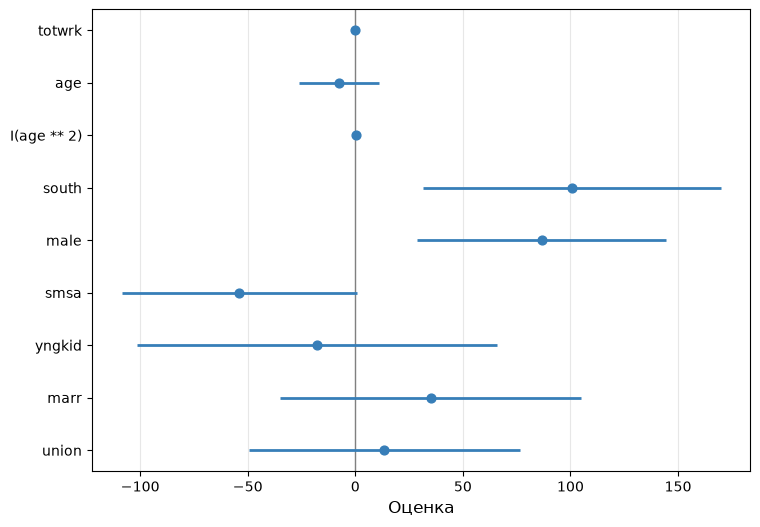

In [7]:
#| label: fig-sleep-ci
#| fig-cap: "sleep equation #2: 90%-доверительные интервалы для коэффициентов"
#| fig-align: "center"
plot_ci(mod, 0.9)

Почему интервалы для `totwrk` и `I(age ** 2)` на рисунке почти не видны? Значит ли это, что эти коэффициенты оценены точнее остальных?

::: {.callout-tip title="Ответ"}
Нет: ширина интервала зависит от единиц измерения регрессора. `totwrk` измерен в минутах в неделю, поэтому коэффициент и его стандартная ошибка малы по величине. Чтобы сравнивать коэффициенты между собой, их приводят к одному масштабу — @fig-sleep-ci-std.
:::

Шкалированный коэффициент показывает, на сколько стандартных отклонений меняется зависимая переменная при увеличении регрессора на одно стандартное отклонение; значимость коэффициентов при шкалировании не меняется.

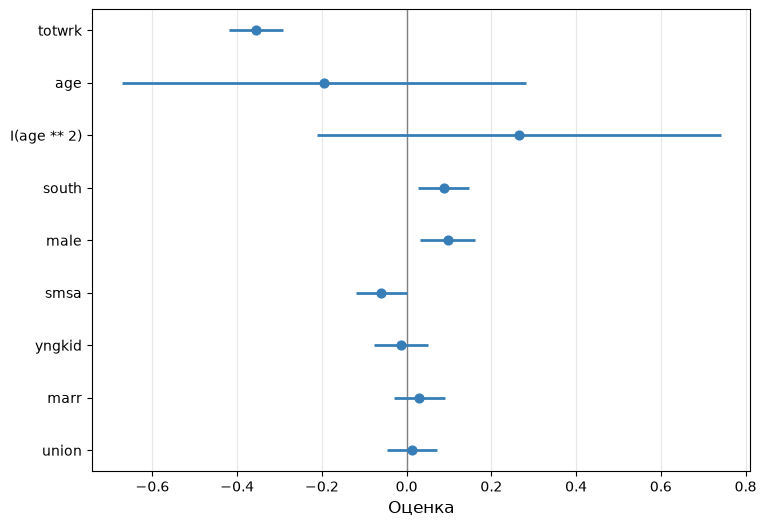

In [8]:
#| label: fig-sleep-ci-std
#| fig-cap: "sleep equation #2: 90%-доверительные интервалы для шкалированных коэффициентов"
#| fig-align: "center"
plot_ci(mod, 0.9, scaled=True)

## cost equation #2

Для набора данных `Electricity` рассмотрим регрессию

```
np.log(cost) ~ np.log(q) + I(np.log(q)**2) + np.log(pl) + I(np.log(pl)**2) +
               np.log(pk) + I(np.log(pk)**2) + np.log(pf) + I(np.log(pf)**2)
```

Ниже приведены 99%-доверительные интервалы для коэффициентов.

In [9]:
#| output: asis
spec = ('np.log(cost) ~ np.log(q) + I(np.log(q)**2) + np.log(pl) + I(np.log(pl)**2)'
        ' + np.log(pk) + I(np.log(pk)**2) + np.log(pf) + I(np.log(pf)**2)')
mod = fit_ols(spec, Electricity, robust=True)
show_ci(mod, 0.99)
show_nobs(mod)
show_conditions(0.01, 'робастные (HC3)',
                r'$H_0:\beta_j=0$ для каждого коэффициента, альтернатива двусторонняя')



**99%-е доверительные интервалы (робастные стандартные ошибки, HC3):**

| Переменная         |   Нижняя граница |   Верхняя граница |
|:-------------------|-----------------:|------------------:|
| Intercept          |         -129.940 |            41.133 |
| np.log(q)          |            0.223 |             0.570 |
| I(np.log(q) ** 2)  |            0.020 |             0.042 |
| np.log(pl)         |          -11.254 |            27.921 |
| I(np.log(pl) ** 2) |           -1.544 |             0.633 |
| np.log(pk)         |           -3.795 |             4.668 |
| I(np.log(pk) ** 2) |           -0.559 |             0.487 |
| np.log(pf)         |           -3.909 |             5.707 |
| I(np.log(pf) ** 2) |           -0.734 |             0.673 |





Модель была подогнана по 158 наблюдениям.





::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **1%**
- стандартные ошибки: **робастные (HC3)**
- гипотеза: $H_0:\beta_j=0$ для каждого коэффициента, альтернатива двусторонняя
:::



Какие коэффициенты значимы?

Коэффициент значим на уровне 1%, если 99%-доверительный интервал не содержит ноль.

In [10]:
#| output: asis
print_significant_coeffs(mod, sign_level=0.01)



::: {.callout-note title="Коэффициенты, значимые на уровне 1% (по робастным стандартным ошибкам HC3)" icon="true"}
`np.log(q)`, `I(np.log(q) ** 2)`
:::



На @fig-cost-ci интервалы показаны в исходных единицах (константа не показана).

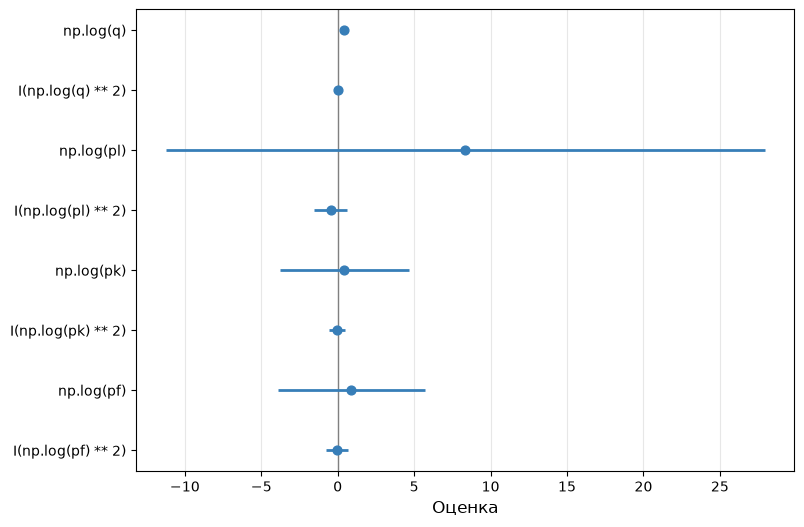

In [11]:
#| label: fig-cost-ci
#| fig-cap: "cost equation #2: робастные 99%-доверительные интервалы для коэффициентов"
#| fig-align: "center"
plot_ci(mod, 0.99)

Почему интервал для `np.log(pl)` намного шире остальных, а интервалы для `np.log(q)` и `I(np.log(q) ** 2)` почти не видны?

::: {.callout-tip title="Ответ"}
Ширина интервала зависит от разброса регрессора: `np.log(pl)` меняется в выборке мало (стандартное отклонение 0.17 против 1.81 у `np.log(q)`). Кроме того, `np.log(pl)` и его квадрат почти линейно зависимы, поэтому оба коэффициента оценены неточно. Чтобы сравнивать коэффициенты между собой, их приводят к одному масштабу — @fig-cost-ci-std: интервал для `np.log(pl)` остаётся самым широким.
:::

Шкалированный коэффициент показывает, на сколько стандартных отклонений меняется зависимая переменная при увеличении регрессора на одно стандартное отклонение; значимость коэффициентов при шкалировании не меняется.

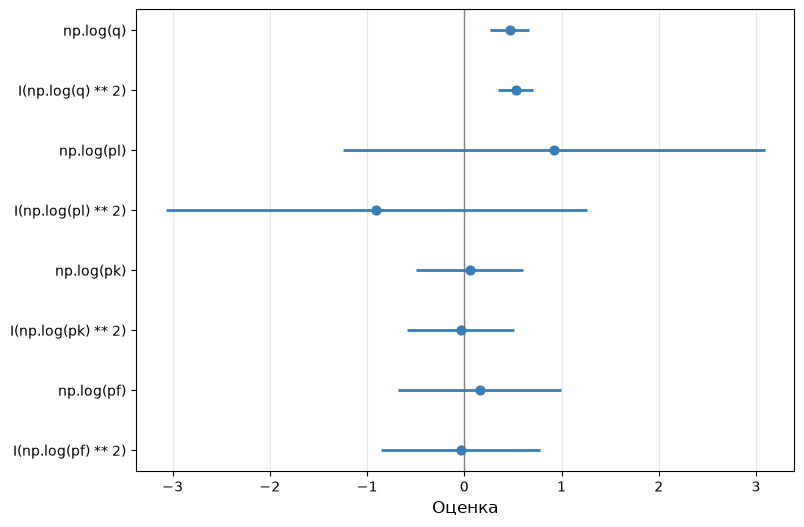

In [12]:
#| label: fig-cost-ci-std
#| fig-cap: "cost equation #2: робастные 99%-доверительные интервалы для шкалированных коэффициентов"
#| fig-align: "center"
plot_ci(mod, 0.99, scaled=True)

# Доверительные интервалы и сравнение моделей

## sleep equation #3

Для набора данных `sleep75` регрессия

`sleep ~ totwrk + age + I(age**2) + smsa + marr`

оценена по трём выборкам: Север (`south = 0`), Юг (`south = 1`) и общая. В таблице — оценки и стандартные ошибки, на @fig-models-ci — 95%-доверительные интервалы.

In [13]:
#| output: asis
spec = 'sleep ~ totwrk + age + I(age**2) + smsa + marr'
order = ['totwrk', 'age', 'I(age ** 2)', 'smsa', 'marr', 'Intercept']
samples = [sleep75[sleep75['south'] == 0], sleep75[sleep75['south'] == 1], sleep75]
models = [fit_ols(spec, df) for df in samples]
show_models(models, names=['Север', 'Юг', 'Общая'], regressor_order=order, info={
    'Observations': lambda m: f'{int(m.nobs)}',
    'Residual Std. Error': lambda m: f'{np.sqrt(m.mse_resid):.3f}',
    'F Statistic': lambda m: f'{m.fvalue:.3f}{signif_stars(m.f_pvalue)}',
})



|                     | Север       | Юг          | Общая       |
|:--------------------|:------------|:------------|:------------|
| Dep. Variable       | sleep       | sleep       | sleep       |
| totwrk              | -0.159***   | -0.074      | -0.147***   |
|                     | (0.018)     | (0.045)     | (0.017)     |
| age                 | -5.507      | -12.882     | -8.675      |
|                     | (12.557)    | (25.039)    | (11.271)    |
| I(age ** 2)         | 0.084       | 0.273       | 0.140       |
|                     | (0.150)     | (0.299)     | (0.135)     |
| smsa                | -59.812*    | 16.055      | -69.924**   |
|                     | (35.379)    | (96.789)    | (32.330)    |
| marr                | 28.034      | 152.296*    | 47.598      |
|                     | (46.960)    | (86.153)    | (41.450)    |
| Intercept           | 3664.188*** | 3435.410*** | 3675.413*** |
|                     | (244.380)   | (494.979)   | (219.803)   |
| R-squared           | 0.129       | 0.140       | 0.118       |
| R-squared Adj.      | 0.122       | 0.106       | 0.112       |
| F Statistic         | 16.928***   | 4.043***    | 18.768***   |
| Observations        | 576         | 130         | 706         |
| Residual Std. Error | 421.078     | 393.300     | 418.809     |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$. В скобках — неробастные стандартные ошибки.



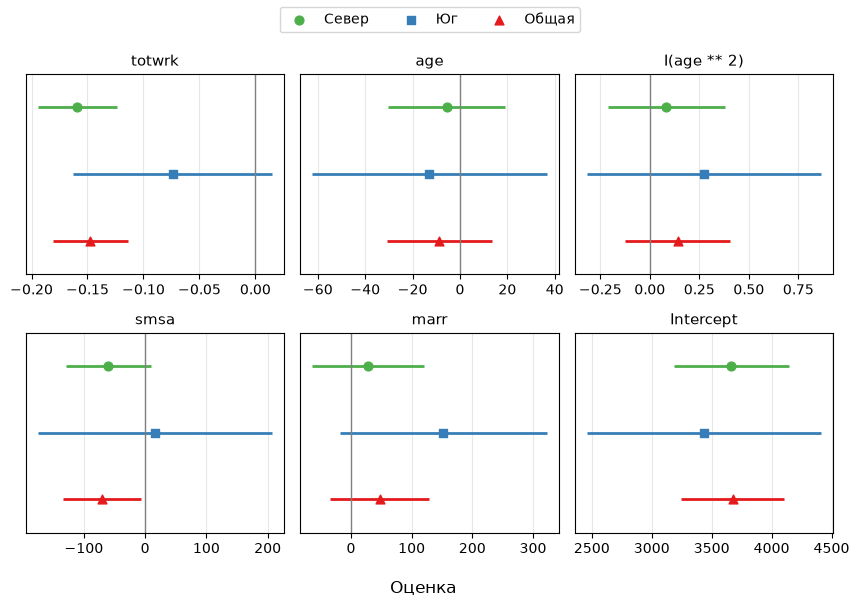

In [14]:
#| label: fig-models-ci
#| fig-cap: "sleep equation #3: 95%-доверительные интервалы для коэффициентов трёх моделей (неробастные стандартные ошибки)"
#| fig-align: "center"
plot_ci_panels(models, ['Север', 'Юг', 'Общая'], 0.95, order)

1. Для каких коэффициентов 95%-доверительные интервалы моделей «Север» и «Юг» не пересекаются?
2. Можно ли по пересечению интервалов сделать вывод, что коэффициенты в двух подвыборках одинаковы? Каким тестом проверяется эта гипотеза?

In [15]:
#| output: asis
north, south = (m.conf_int(alpha=0.05) for m in models[:2])
assert ((north[0] <= south[1]) & (south[0] <= north[1])).all()  # ответ ниже: пересекаются все

::: {.callout-tip title="Ответ"}
Интервалы пересекаются для всех коэффициентов. Пересечение интервалов не является тестом равенства коэффициентов; гипотеза об отсутствии структурных сдвигов проверяется F-тестом (тест Чоу), см. листок list07-F-test.
:::